# Leaf traits inversion

In this tutorial, you will get hands on **PROSPECT, a model of leaf optical properties**:<br>
* [1] *Féret, J. B., Gitelson, A. A., Noble, S. D., & Jacquemoud, S. J. R. S. O. E. (2017). PROSPECT-D: Towards modeling leaf optical properties through a complete lifecycle. Remote Sensing of Environment, 193, 204-215.* 
* [2] *Jacquemoud, S., & Baret, F. (1990). PROSPECT: A model of leaf optical properties spectra. Remote sensing of environment, 34(2), 75-91.*

<center>
    <img src="prospect.png" width=700>

    HIgh-level illustration of PROSPECT for forward and inverse modeling. Credit: Jean-Baptiste Féret.
</center>

<br>

We call leaf traits the physical, biological, and chemical properties of the leaves. In particular, "three main families of pigments are found in leaves: **chlorophylls, carotenoids, and anthocyanins**" [1]. The dynamics of those pigments "directly affects nutrient, nitrogen, carbon and water cycles (Shipley et al., 2006; Joiner et al., 2011)", making them "**good indicators of changes in environmental conditions** from local to global scales." [1]

#### PROSPECT model: From bio-physical properties to optical properties

The PROSPECT model "assumes that **leaves are composed of N homogeneous plate layers separated by N-1 air layers**". "By inputting different parameters and corresponding **spectral absorption coefficients of leaf biochemical constituents** such as the content of chlorophyll, water, and dry matter, the **hemispherical reflectance and transmittance** of plant leaves across the 400–2500 nm wavelength range can be simulated." [3]

<center>
    <img src="prospect_model.jpg" width=500>
    
    Illustration of the PROSPECT model [1, 2]. Figure reproduced from [3]. 
</center>

<br>

**The model is calibrated and validated against paired measurements of leaf optics and leaf biochemistry.** In particular, the specific absorption coefficients of chlorophylls, carotenoids, and anthocyanins used by the PROSPECT model are plotted below:

<center>
    <img src="sacs_feret.png" width=500>
    
    Specific absorption coefficients (SAC) of chlorophylls (green), carotenoids (orange), and anthocyanins (red). The solids line correspond to the SAC of all the pigments in PROSPECT-D, the dashed lines to the SAC of chlorophylls and carotenoids in PROSPECT-5, and to the SAC of anthocyanins measured by Peters and Noble (2014) using thin layer chromatography. Figure and caption reproduced from [1]. 
</center>

<br> 

The total absorption is the sum of the concentrations of each constituent (chlorophylls, carotenoids, anthocyanins, water/brown pigments, dry matter) times their specific absorption coefficients.

[3] *Yu, F., Xiang, S., Jin, Z., Bai, J., & Xu, T. (2026). Advancements in Leaf-Scale Radiative Transfer Modeling: A Review with Focus on the PROSPECT Model. Agriculture Communications, 100122.*

In [1]:
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    !git clone https://github.com/Romain3Ch216/RSFM.git
    import sys
    sys.path.insert(0, "/content/RSFM/tree/main/docs/tutorials/basics_radiative_transfer_modeling")
    sys.path.insert(0, "/content/RSFM/tree/main/docs/tutorials/leaf_traits_inversion")
    !pip install pandas
    !pip install Py6S

## Forward modeling

First, we will use a Python interface to run the PROSPECT model: https://github.com/jgomezdans/prosail/tree/master

In [2]:
import os
import sys
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import prosail

sys.path.append('../basics_radiative_transfer_modeling')

from utils.utils import plot_dict

Below, we define for each leaf parameter the default value and intervals commonly used in the literature. 

In [3]:
LEAF_TRAITS = {
    'N': {'desc': 'Leaf structure parameter', 'range': [1.0, 2.5], 'default': 1.5, 'unit': None},
    'Cab': {'desc': 'Chlorophyll a+b concentration', 'range': [20, 80], 'default': 40, 'unit': 'µg/cm²'},
    'Car': {'desc': 'Cartenoid concentration', 'range': [3, 15], 'default': 8, 'unit': 'µg/cm²'},
    'Cbrown': {'desc': 'Brown pigment', 'range': [0, 1], 'default': 0, 'unit': None},
    'Cw': {'desc': 'Equivalent water thickness', 'range': [0.005, 0.04], 'default': 0.015, 'unit': 'cm'},
    'Cm': {'desc': 'Dry matter', 'range': [0.002, 0.02], 'default': 0.009, 'unit': 'g/cm²'}
}

Use PROSPECT to simulate reflectance spectra from 0.4 µm to 2.5 µm for varying values of leaf traits. See https://github.com/jgomezdans/prosail/blob/master/prosail/prospect_d.py on how to call the PROSPECT-D model. Implement a function named `call_prospect`.

In [4]:
def call_prospect(N: float, Cab: float, Car: float, Cbrown: float, Cw: float, Cm: float, downsample_factor: int = 6):
    """
    Call the PROSPECT-D model.

    Args:
        N: Leaf structure parameter
        Cab: Chlorophyll a+b concentration
        Car: Cartenoid concentration
        Cbrown: Brown pigment
        Cw: Equivalent water thickness
        Cm: Dry matter
        downsample_factor: PROSPECT returns a reflectance spectrum of size 2501.
            Use downsample_factor > 1 to uniformly sample the outputs.
        
    Returns:
        a tuple containing two arrays corresponding to
        wavelengths and reflectance.
    """
    # <CORRECTION>
    assert N >= LEAF_TRAITS['N']['range'][0] and N<= LEAF_TRAITS['N']['range'][1]
    assert Cab >= LEAF_TRAITS['Cab']['range'][0] and Cab<= LEAF_TRAITS['Cab']['range'][1]
    assert Car >= LEAF_TRAITS['Car']['range'][0] and Car<= LEAF_TRAITS['Car']['range'][1]
    assert Cbrown >= LEAF_TRAITS['Cbrown']['range'][0] and Cbrown<= LEAF_TRAITS['Cbrown']['range'][1]
    assert Cw >= LEAF_TRAITS['Cw']['range'][0] and Cw<= LEAF_TRAITS['Cw']['range'][1]
    assert Cm >= LEAF_TRAITS['Cm']['range'][0] and Cm<= LEAF_TRAITS['Cm']['range'][1]
    
    lam, rho, _ = prosail.run_prospect(N, Cab, Car, Cbrown, Cw, Cm)

    return lam[::downsample_factor], rho[::downsample_factor]
    # </CORRECTION>

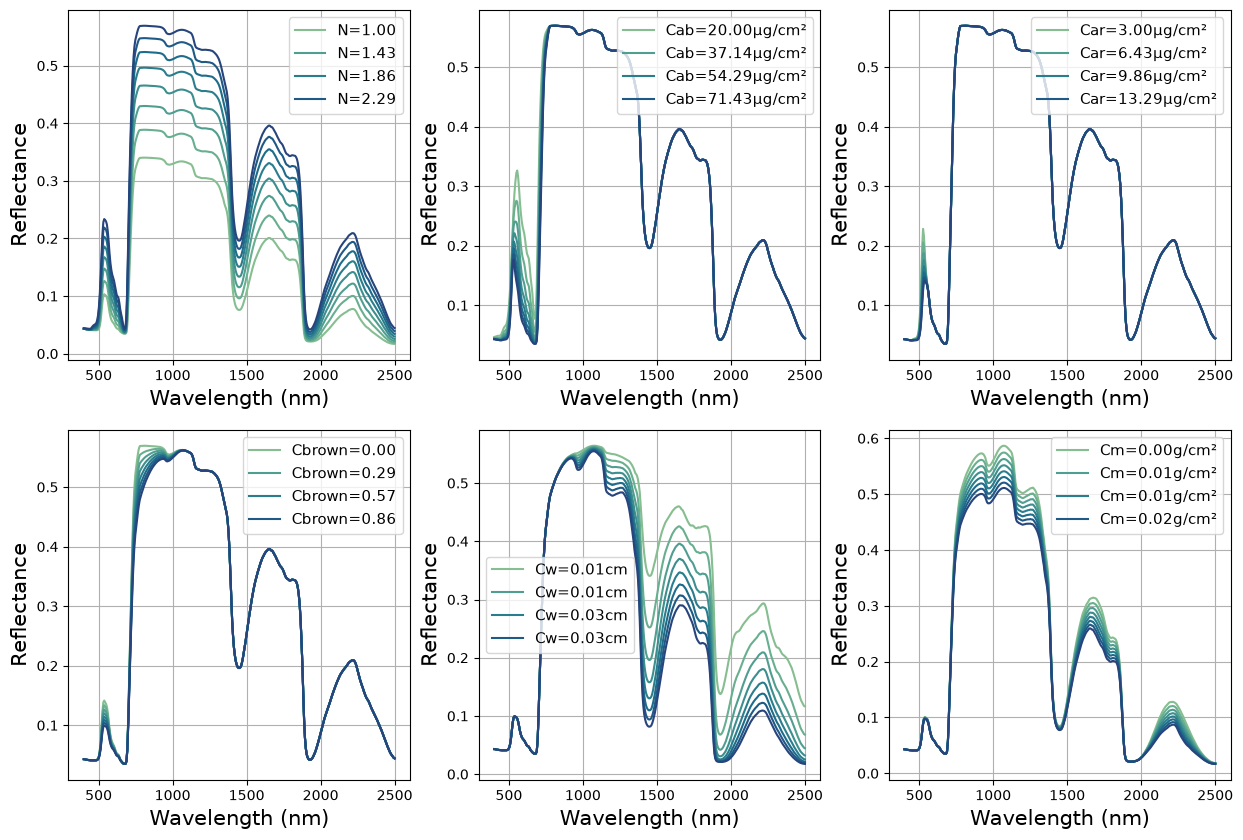

In [5]:
n_values = 8
fontsize = 15

colors = sns.color_palette("crest", n_values)
traits = dict((k, v['default']) for k, v in LEAF_TRAITS.items())

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for trait, ax in zip(LEAF_TRAITS, axs.flat):
    # <CORRECTION>
    range_trait = LEAF_TRAITS[trait]['range']
    trait_values = np.linspace(range_trait[0], range_trait[1], n_values)
    # </CORRECTION>
    for i, trait_value in enumerate(trait_values):
        traits[trait] = trait_value
        lam, rho = call_prospect(**traits)
        unit = LEAF_TRAITS[trait]['unit'] if LEAF_TRAITS[trait]['unit'] is not None else ''
        label = f'{trait}={trait_value:.2f}{unit}' if i % 2 == 0 else None
        ax.plot(lam, rho, color=colors[i], label=label)
        
    ax.set_xlabel(f'Wavelength (nm)', fontsize=fontsize)
    ax.set_ylabel('Reflectance', fontsize=fontsize)
    ax.legend(fontsize=int(0.75*fontsize))
    ax.grid()

plt.show()

## Inverse modeling

Now, we will invert the PROSPECT model to estimate leaf traits from reflectance spectra. There are many methods to invert a forward model. Here, we will use methods based on Look-Up Tables (LUT).


#### Look-up Tables

In our context, LUTs are data bases generated by forward models (here the PROSPECT model) for a very large amount of input parameters. LUTs are usually pre-computed because the forward modeling can be time expensive. "Lookup tables (LUTs) are an excellent technique for optimizing the evaluation of functions that are expensive to compute and inexpensive to cache. ... For data requests that fall between the table's samples, an interpolation algorithm can generate reasonable approximations by averaging nearby samples." [NVIDIA article](https://developer.nvidia.com/gpugems/gpugems2/part-iii-high-quality-rendering/chapter-24-using-lookup-tables-accelerate-color)


Then, the inversion of the model, given a reflectance spectrum, simply consists in retrieving the leaf traits that correspond to the most similar spectrum in the LUT.

Let us implement a function `parameters_random_sampling` that computes an array of leaf traits by randomly sampling within the specified intervals, and a function `build_lut` that runs the forward model given the array of leaf traits.

In [6]:
def parameters_random_sampling(list_bounds: list[tuple[float, float]], n_samples: int) -> np.ndarray:
    """Builds a table of parameter combinations by random sampling.

    Each parameter is randomly sampled within its bounds, and the
    Cartesian product of all discretized parameters is enumerated, one
    combination per row.

    Args:
        list_bounds: a list of (min, max) pairs, one per parameter.
        n_samples: number of samples to draw.

    Returns:
        an array of size n_values**n_parameters x n_parameters.
    """
    # <CORRRECTION>
    parameters = np.random.rand(n_samples, len(list_bounds))
    low_bounds = np.array([bound[0] for bound in list_bounds]).reshape(1, -1)
    size_bounds = np.array([bound[1] - bound[0] for bound in list_bounds]).reshape(1, -1)
    parameters = low_bounds + parameters * size_bounds
    # </CORRRECTION>
    return parameters

def build_lut(
    parameters: np.ndarray,
    forward_model: Callable[[np.ndarray], np.ndarray],
) -> tuple[np.ndarray, np.ndarray]:
    """Builds a Look-Up Table by evaluating a forward model on given parameters.

    Args:
        parameters: array of parameters of shape (n_entries, n_parameters)
        forward_model: maps a parameter vector to its simulated output
            (e.g. a reflectance spectrum).

    Returns:
        a array of size (n_entries, n_outputs)
    """
    # <CORRECTION>    
    output_table = np.stack(
        [forward_model(*params) for params in parameters]
    )
    output_table = output_table[:, 1, :]
    # </CORRECTION>
    return output_table

In [7]:
traits = list(LEAF_TRAITS.keys())
bounds = [LEAF_TRAITS[trait]['range'] for trait in traits]
traits_table = parameters_random_sampling(bounds, n_samples=10000)
reflectance_table = build_lut(traits_table, forward_model=call_prospect)

Let's model a new reflectance spectrum, and estimate its leaf traits.

In [8]:
import random

new_traits = dict((k, random.uniform(v['range'][0], v['range'][1])) for (k, v) in LEAF_TRAITS.items())
lam, test_reflectance = call_prospect(**new_traits)

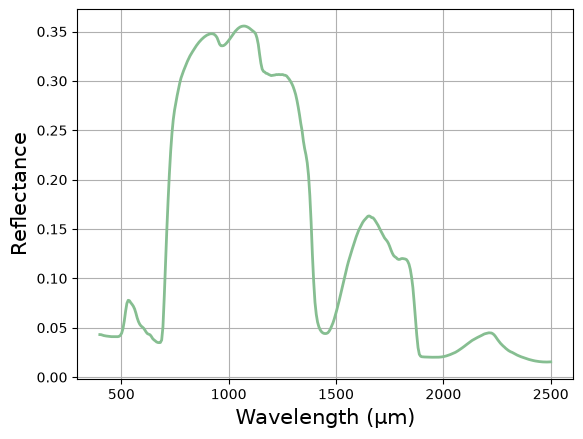

In [9]:
fig, ax = plt.subplots()
ax.plot(lam, test_reflectance, color=colors[0], label=label, lw=2)
ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
ax.set_ylabel('Reflectance', fontsize=fontsize)
ax.grid()
plt.show()

In [10]:
from scipy.spatial.distance import cdist

def compute_distances(query: np.ndarray, reference: np.ndarray) -> np.ndarray:
    """Computes the euclidean distance between a query vector and reference vectors.

    Args:
        query: an array of shape n_features
        reference: an array of shape (n_entries, n_features)

    Returns:
        an array of size n_entries
    """
    # <CORRECTION>
    if len(query.shape) < 2:
        query = query.reshape(1, -1)
    dist = cdist(query, reference)
    # </CORRECTION>
    return dist


def lut_inversion(observation: np.ndarray, lut_entries: np.ndarray, lut_parameters: np.ndarray, top_k: int = 1):
    """Inverts a forward model via nearest-neighbor lookup in a LUT.

    Args:
        observation: measured data of size n_features
        lut_entries: simulated data of size (n_entries, n_features)
        lut_parameters: parameter values of size (n_entries, n_parameters)
        top_k: number of nearest entries to retrieve

    Returns:
        the parameters of the top_k nearest LUT entries
    """
    # <CORRECTION>
    distances = compute_distances(observation, lut_entries)
    # import pdb; pdb.set_trace()
    nearest_indices = np.argsort(distances, axis=-1)[:, :top_k]
    return lut_parameters[nearest_indices], lut_entries[nearest_indices]
    # </CORRECTION>

def inversion_metrics(y_pred: np.ndarray, y_true: np.ndarray):
    """Computes the absolute, relative error, and coefficient of determination
    between the predicted and true values. The coefficient of determination is 
    defined by:
        R^2 = 1 - \sum_i (y_pred_i - y_true_i)^2 / \sum_i (y_true_i - mean(y_true))^2
    See https://fr.wikipedia.org/wiki/Coefficient_de_d%C3%A9termination.

    Args:
        y_pred: prediction array of shape (n_solutions, n_variables)
        y_true: ground truth array of shape n_variables
    """
    # <CORRECTION>
    if isinstance(y_true, dict):
        y_true = np.array(list(y_true.values())).reshape(1, -1)

    assert y_true.shape[-1] == y_pred.shape[-1]
    y_true = y_true[:, np.newaxis, :]
            
    error = y_pred - y_true
    abs_error = np.mean(np.abs(error), axis=0)
    relative_error = np.mean(error / y_true * 100, axis=0)

    if y_pred.shape[0] > 1:
        ss_res = np.sum((y_pred - y_true)**2, axis=0)
        ss_tot = np.sum((y_true - np.mean(y_true, axis=0))**2, axis=0)
        r2_score = 1 - ss_res / ss_tot
    else:
        r2_score = None
    # </CORRECTION>
    return abs_error, relative_error, r2_score

<>:44: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:44: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/ipykernel_75387/3064435286.py:44: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  R^2 = 1 - \sum_i (y_pred_i - y_true_i)^2 / \sum_i (y_true_i - mean(y_true))^2


In [11]:
estimated_leaf_traits, closest_spectra = lut_inversion(test_reflectance, reflectance_table, traits_table, top_k=3)
abs_error, relative_error, r2_score = inversion_metrics(estimated_leaf_traits, new_traits)
abs_error[0]

array([6.49046861e-02, 4.75773329e-01, 2.73062017e+00, 1.03479021e-01,
       5.90039391e-04, 3.88407293e-03])

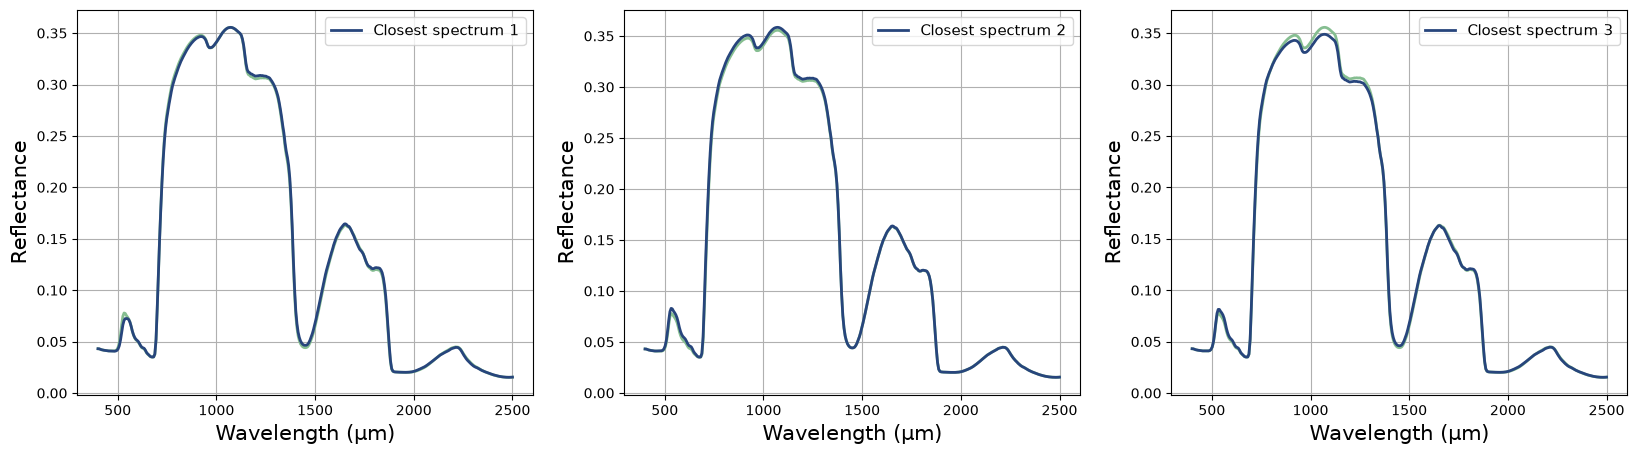

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
for i, ax in enumerate(axs.flat):
    ax.plot(lam, test_reflectance, color=colors[0], lw=2)
    ax.plot(lam, closest_spectra[0, i], color=colors[-1], lw=2, label=f'Closest spectrum {i+1}')
    ax.legend(fontsize=int(0.75*fontsize))
    ax.grid()
    ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
    ax.set_ylabel('Reflectance', fontsize=fontsize)
plt.show()

Let's sample 1000 test samples, and plot the predicted leaf traits against the true parameters.

In [13]:
# <CORRECTION>
test_leaf_traits = parameters_random_sampling(bounds, n_samples=1000)
test_reflectance = build_lut(test_leaf_traits, forward_model=call_prospect)
estimated_leaf_traits, closest_spectra = lut_inversion(test_reflectance, reflectance_table, traits_table, top_k=1)
abs_error, relative_error, r2_score = inversion_metrics(estimated_leaf_traits, test_leaf_traits)
# </CORRECTION>

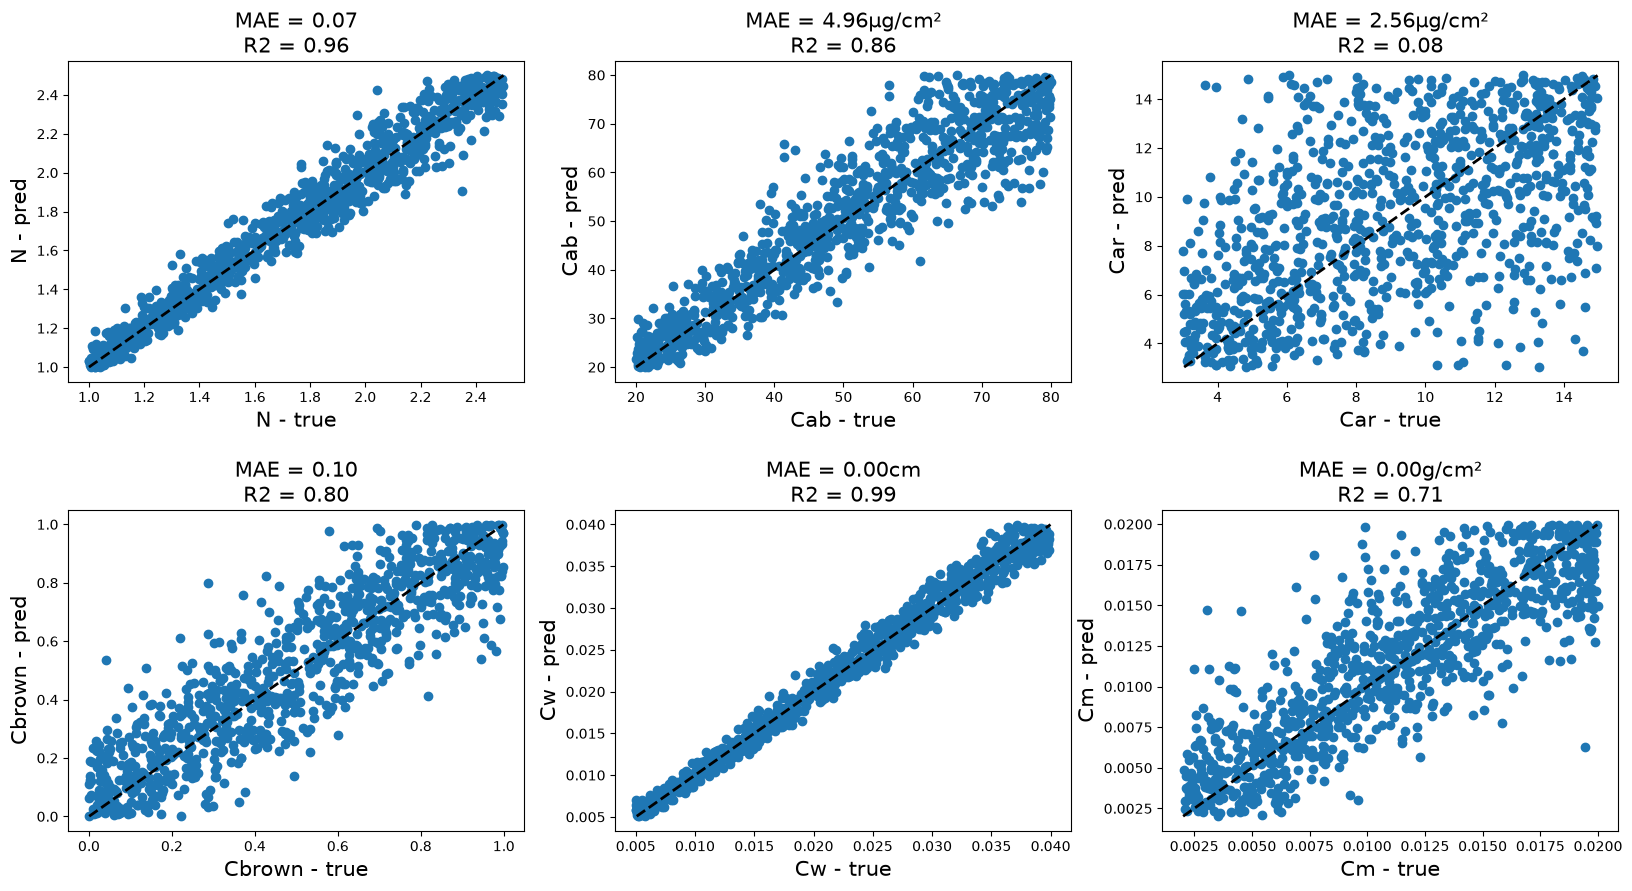

In [14]:
fig, axs = plt.subplots(2, estimated_leaf_traits.shape[2] // 2, figsize=(20, 10))
fig.subplots_adjust(hspace=0.4)

trait_labels = list(LEAF_TRAITS.keys())
units = [LEAF_TRAITS[trait]['unit'] if LEAF_TRAITS[trait]['unit'] is not None else '' for trait in trait_labels]

# <CORRECTION>
for i, ax in zip(range(estimated_leaf_traits.shape[2]), axs.flat):
    x = np.linspace(estimated_leaf_traits[:, 0, i].min(), estimated_leaf_traits[:, 0, i].max(), 100)
    ax.plot(x, x, linestyle='--', lw=2, color='black')
    ax.scatter(test_leaf_traits[:, i], estimated_leaf_traits[:, 0, i])
    ax.set_title(f'MAE = {abs_error[0, i]:.2f}' + units[i] + f'\nR2 = {r2_score[0,i]:.2f}', fontsize=fontsize)
    ax.set_ylabel(f'{trait_labels[i]} - pred', fontsize=fontsize)
    ax.set_xlabel(f'{trait_labels[i]} - true', fontsize=fontsize)
plt.show()
# </CORRECTION>

Update the `apply_spectral_response_function` function implemented in tutorial 1 in order to handle arrays of shape (n_samples, len(wv)) instead of arrays of shape (len(wv)). Use `scipy.interpolate.interp1d`. 

In [15]:
from scipy.interpolate import interp1d

def apply_spectral_response_function(wv: np.ndarray, x: np.ndarray, srf: Dict):
    """Convolve spectra with a Spectral Response Function.
    
    Args:
        wv: original array of wavelengths, e.g. np.linspace(0.45, 2.5, 100)
        x: spectra of shape (n_samples, len(wv))
        srf: spectral function response of Sentinel-2, 
                dict of bands, each with 'wv' and 'srf' arrays
        
    Returns:
        a n_samples x len(s2_srf) array
    """
    output_dict = {}
    # f = interp1d(...)
    # <CORRECTION>
    f = interp1d(wv, x, axis=1, bounds_error=0, fill_value=0)
    # </CORRECTION>
    for i, band in enumerate(srf):
        # <CORRECTION>
        x_on_srf_wv = f(srf[band]['wv'])
        # </CORRECTION>
        num = np.trapezoid(
            # <CORRECTION>
            x_on_srf_wv * srf[band]['srf'], srf[band]['wv']
            # </CORRECTION>
        )
        den = np.trapezoid(srf[band]['srf'], srf[band]['wv'])
        output_dict[band] = num /den

    output = np.stack(list(output_dict.values())).T
    return output

def compute_wv_from_metadata(wv: Dict, step: float):
    """Compute the wavelengths that correspond to the SFR.
    Args:
        wv: dict with keys 'MIN_WV' and 'MAX_WV'
        step: step in nm
    """
    # <CORRECTION>
    return (wv['MIN_WV'] + step * np.arange(wv['MAX_WV'] - wv['MIN_WV'] + 1)) / 1000 # µm
    # </CORRECTION>

In [16]:
from eodal_s2_parsing import parse_MTD_MSI

data_folder = '../../../../data/S2B_MSIL1C_20261005T102859_N0513_R108_T31UGP_20261005T140445.SAFE/'
metadata = parse_MTD_MSI(os.path.join(data_folder, 'MTD_MSIL1C.xml'))
plot_dict(metadata)

,type,value_preview
key,,
PRODUCT_URI,str,'S2B_MSIL1C_20261005T102859_N0513_R108_T31UGP_...
PROCESSING_LEVEL,str,'Level-1C'
SENSING_ORBIT_NUMBER,str,'108'
SPACECRAFT_NAME,str,'Sentinel-2B'
SENSING_ORBIT_DIRECTION,str,'DESCENDING'
...,...,...
SFR_B8A,dict,{'VALUES': '0.01055777 0.03225389 0.07341127 0...
SFR_B09,dict,{'VALUES': '0.00416917 0.04602242 0.15140822 0...
SFR_B10,dict,{'VALUES': '0.00138452 0.00755083 0.02312566 0...


In [17]:
S2_BANDS = ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B10', 'B11', 'B12']
s2_srf = dict((band, metadata[f'SFR_{band}']) for band in S2_BANDS)
for band, sfr in s2_srf.items():
    s2_srf[band]['srf'] = [float(x) for x in sfr['VALUES'].split(' ')] # split the string in sfr['VALUES'] and convert to floats
    s2_srf[band]['wv'] = compute_wv_from_metadata(metadata[f'WAVELENGTHS_{band}'], float(sfr['STEP']))

In [18]:
# <CORRECTION>
s2_reflectance_table = apply_spectral_response_function(lam / 1000, reflectance_table, s2_srf)
test_s2_reflectance = apply_spectral_response_function(lam / 1000, test_reflectance, s2_srf)
# </CORRECTION>
estimated_leaf_traits, closest_s2_spectra = lut_inversion(test_s2_reflectance, s2_reflectance_table, traits_table, top_k=3)
abs_error, relative_error, r2_score = inversion_metrics(estimated_leaf_traits, test_leaf_traits)
abs_error[0]

array([9.03127106e-02, 3.70681631e+00, 2.91267592e+00, 8.33135566e-02,
       1.36457060e-03, 3.02535794e-03])

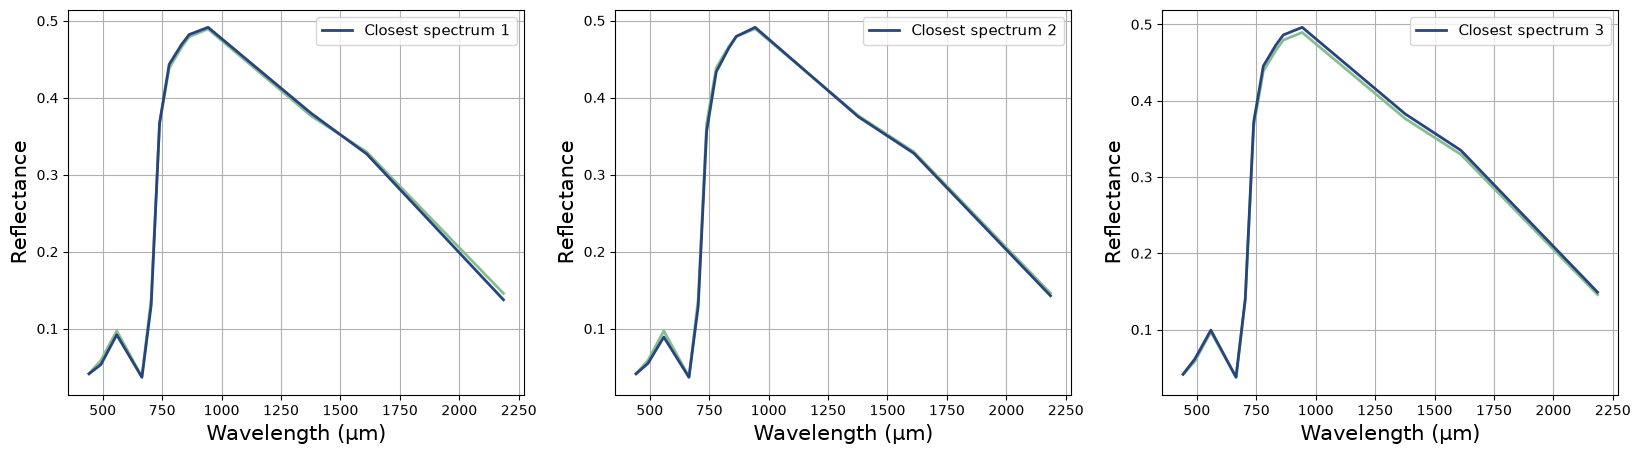

In [19]:
s2_central_wv = [metadata[f'WAVELENGTHS_{band}']['CENTRAL_WV'] for band in S2_BANDS]

# <CORRECTION>
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
for i, ax in enumerate(axs.flat):
    ax.plot(s2_central_wv, test_s2_reflectance[0], color=colors[0], lw=2)
    ax.plot(s2_central_wv, closest_s2_spectra[0, i], color=colors[-1], lw=2, label=f'Closest spectrum {i+1}')
    ax.legend(fontsize=int(0.75*fontsize))
    ax.grid()
    ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
    ax.set_ylabel('Reflectance', fontsize=fontsize)
plt.show()
# </CORRECTION>

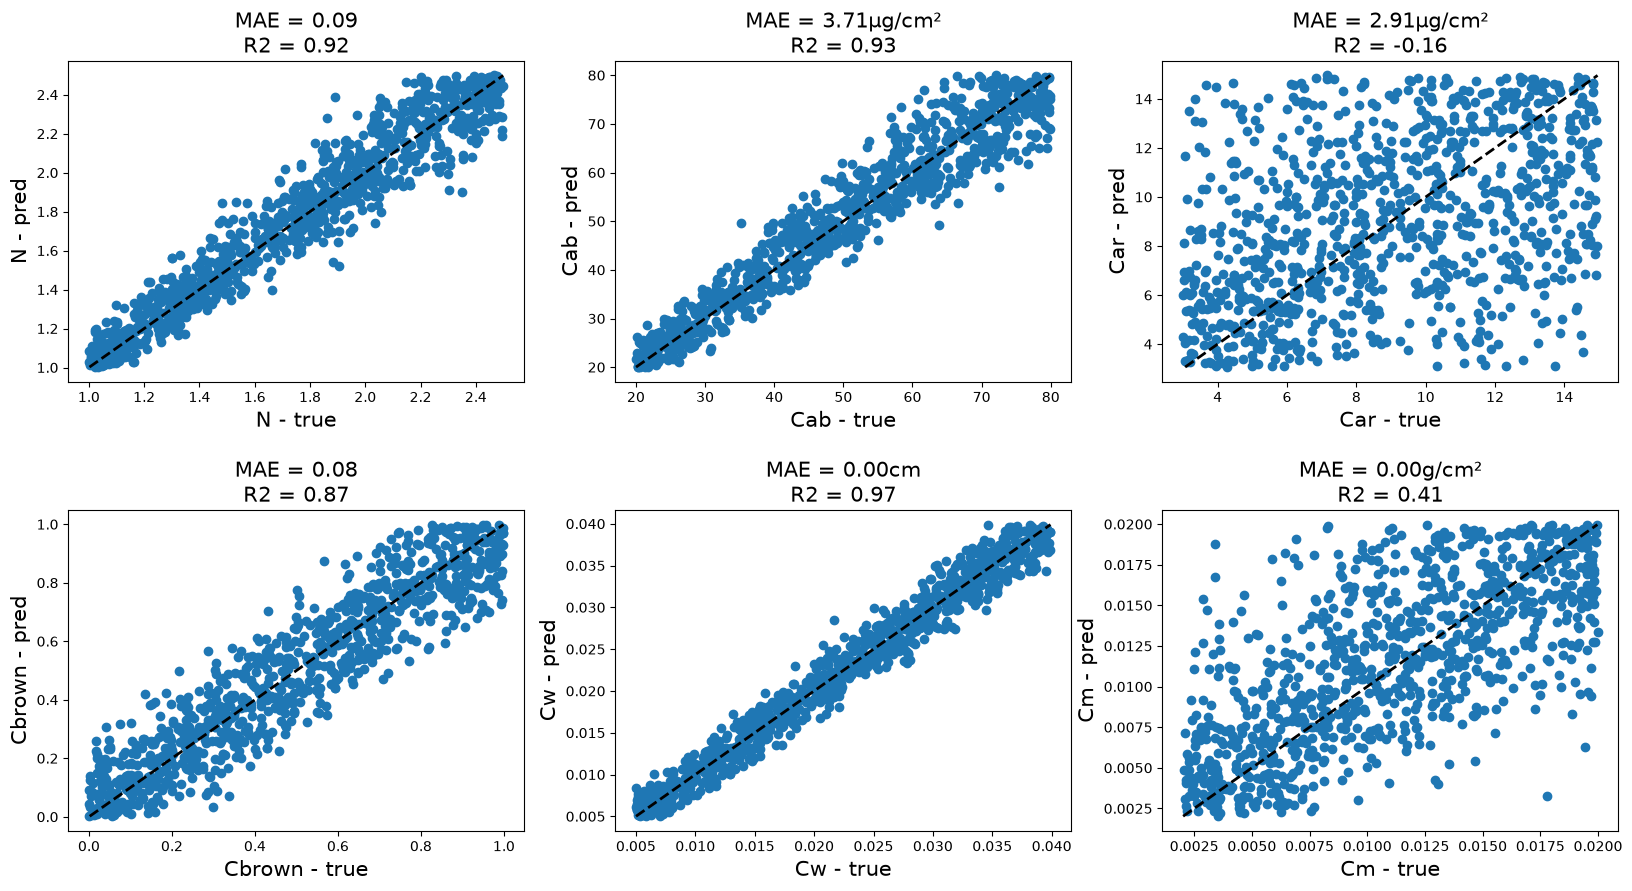

In [20]:
fig, axs = plt.subplots(2, estimated_leaf_traits.shape[2] // 2, figsize=(20, 10))
fig.subplots_adjust(hspace=0.4)

# <CORRECTION>
for i, ax in zip(range(estimated_leaf_traits.shape[2]), axs.flat):
    x = np.linspace(estimated_leaf_traits[:, 0, i].min(), estimated_leaf_traits[:, 0, i].max(), 100)
    ax.plot(x, x, linestyle='--', lw=2, color='black')
    ax.scatter(test_leaf_traits[:, i], estimated_leaf_traits[:, 0, i])
    ax.set_title(f'MAE = {abs_error[0, i]:.2f}' + units[i] + f'\nR2 = {r2_score[0,i]:.2f}', fontsize=fontsize)
    ax.set_ylabel(f'{trait_labels[i]} - pred', fontsize=fontsize)
    ax.set_xlabel(f'{trait_labels[i]} - true', fontsize=fontsize)
plt.show()
# </CORRECTION>

From this toy experiment, can we conclude that the multispectral instrument of Sentinel-2 is well-suited for vegetation monitoring? Are the RGB channels enough?

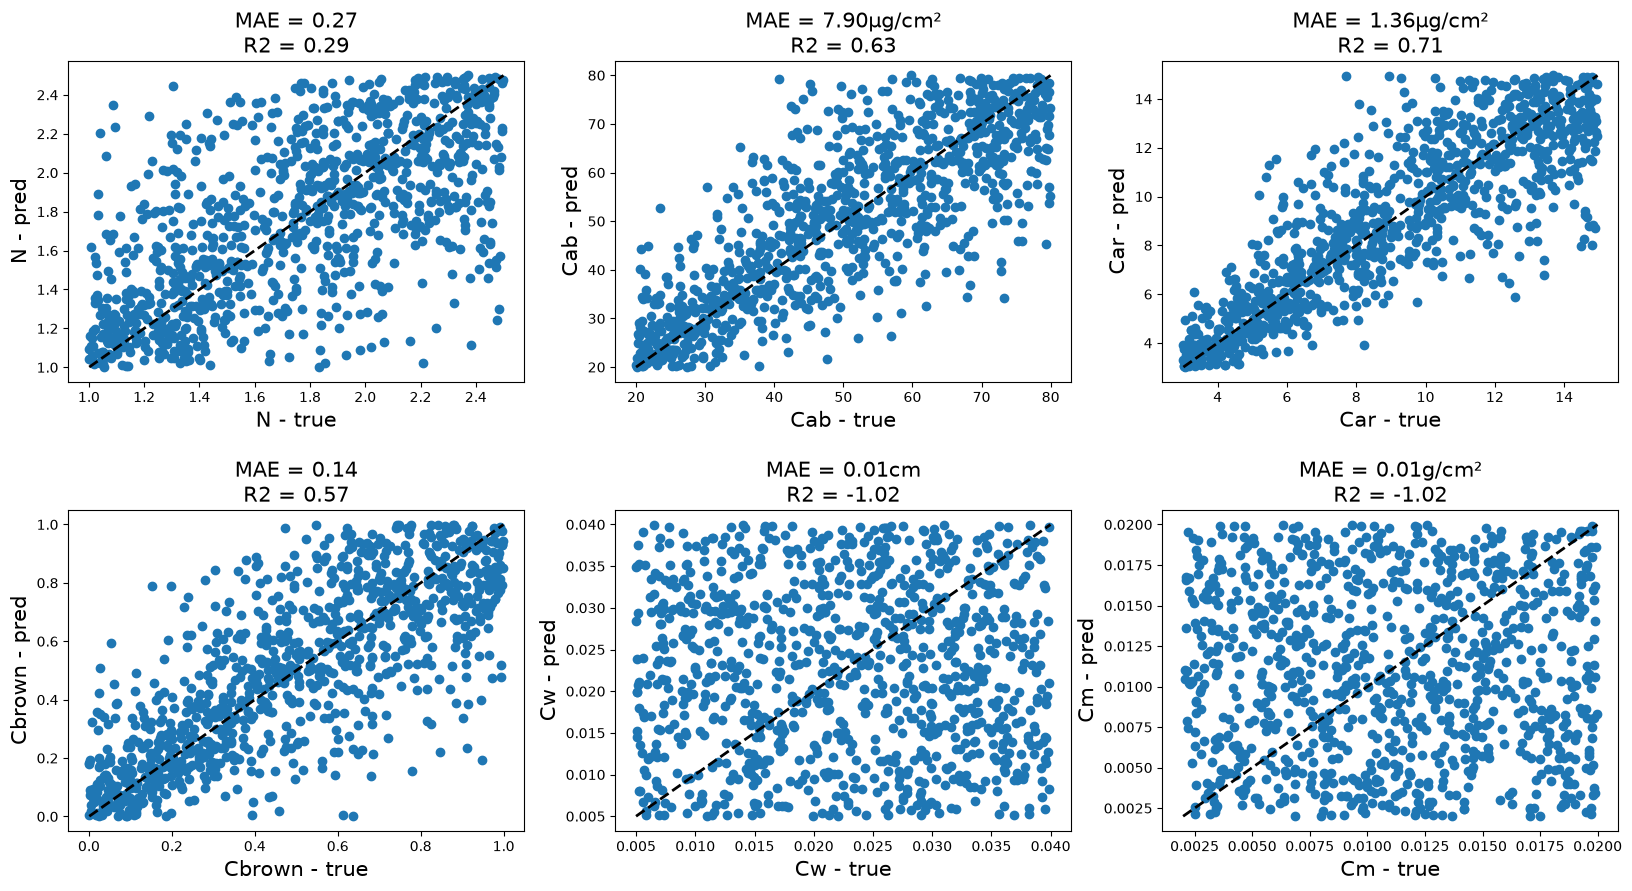

In [21]:
# <CORRECTION>
rgb_nir = np.array([1, 2, 3])
estimated_leaf_traits, closest_spectra = lut_inversion(test_s2_reflectance[:, rgb_nir], s2_reflectance_table[:, rgb_nir], traits_table, top_k=1)
abs_error, relative_error, r2_score = inversion_metrics(estimated_leaf_traits, test_leaf_traits)
# </CORRECTION>

fig, axs = plt.subplots(2, estimated_leaf_traits.shape[2] // 2, figsize=(20, 10))
fig.subplots_adjust(hspace=0.4)

# <CORRECTION>
for i, ax in zip(range(estimated_leaf_traits.shape[2]), axs.flat):
    x = np.linspace(estimated_leaf_traits[:, 0, i].min(), estimated_leaf_traits[:, 0, i].max(), 100)
    ax.plot(x, x, linestyle='--', lw=2, color='black')
    ax.scatter(test_leaf_traits[:, i], estimated_leaf_traits[:, 0, i])
    ax.set_title(f'MAE = {abs_error[0, i]:.2f}' + units[i] + f'\nR2 = {r2_score[0,i]:.2f}', fontsize=fontsize)
    ax.set_ylabel(f'{trait_labels[i]} - pred', fontsize=fontsize)
    ax.set_xlabel(f'{trait_labels[i]} - true', fontsize=fontsize)
plt.show()
# </CORRECTION>

## Effects of the estimation of BOA reflectance on leaf traits inversion

As we have seen in tutorial 1, algorithms used to estimate BOA reflectance from TOA radiance usually assume that the ground is flat. Therefore, the irradiance is assumed to be uniform over the image. For instance, shadows are not corrected. We are going to simulate the variations of estimated reflectance that variations of direct irradiance would cause.

Let's use the auxiliary data of the Sentinel-2 image we have already downloaded to simulate BOA direct and diffuse irradiance.

In [22]:
import glob 
from eodal_s2_parsing import parse_MTD_TL
from parse_auxiliary_data import get_atmosphere_data
from radiative_transfer_modeling import radiative_transfer_modeling_6S


aux_geometry_data = parse_MTD_TL(glob.glob(os.path.join(data_folder, 'GRANULE/*/MTD_TL.xml'))[0])

aux_atmosphere_data = get_atmosphere_data(
    data_folder,
    lat=aux_geometry_data['ULX'],
    lon=aux_geometry_data['ULY'])

aux_data = {
    'AUX_GEOMETRY_DATA': aux_geometry_data,
    'AUX_ATMOSPHERIC_DATA': aux_atmosphere_data
}

radiative_variables = radiative_transfer_modeling_6S(aux_data, lam / 1000)

ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represen

In [23]:
traits = dict((k, v['default']) for k, v in LEAF_TRAITS.items())
lam, reflectance = call_prospect(**traits)

In [24]:
theta = aux_data['AUX_GEOMETRY_DATA']['SUN_ZENITH_ANGLE']
I_dir = np.array(radiative_variables['DIRECT_SOLAR_IRRADIANCE']['VALUES'])
I_dif = np.array(radiative_variables['DIFFUSE_SOLAR_IRRADIANCE']['VALUES'])
print(f"Sun zenith angle: {theta:.2f}deg")
theta = theta * np.pi / 180

Sun zenith angle: 53.95deg


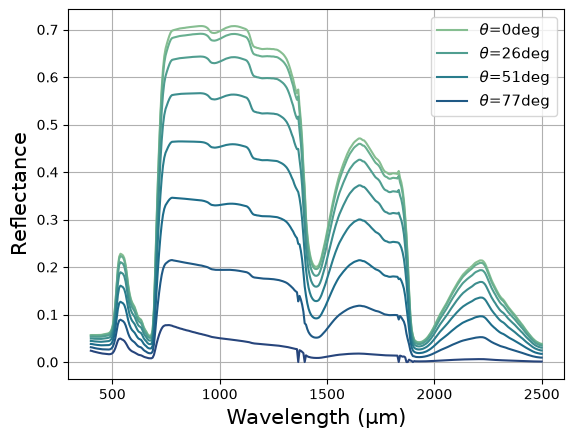

In [25]:
fig, ax = plt.subplots()
for i, theta_true in enumerate(np.linspace(0, np.pi / 2, n_values)):
    # reflectance_hat = ...
    # <CORRECTION>
    reflectance_hat = (I_dir * np.cos(theta_true) + I_dif) / (I_dir * np.cos(theta) + I_dif) * reflectance    
    # </CORRECTION>
    label = r'$\theta$' + f'={theta_true * 180 / np.pi:.0f}deg' if i % 2 == 0 else None
    ax.plot(lam, reflectance_hat, color=colors[i], label=label)
ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
ax.set_ylabel('Reflectance', fontsize=fontsize)
ax.legend(fontsize=int(0.75*fontsize))
ax.grid()
plt.show()

What would be the impact on the inversion of leaf traits?

## Leaf traits estimation from Sentinel-2 data

We are going to perform leaf traits estimation from Sentinel-2 data from the following dataset: <br>
*Petr Lukeš. (2023). Plant functional traits and corresponding satellite multispectral data for two sites in the Czech Republic [Dataset]. Zenodo. https://doi.org/10.5281/zenodo.7913007*

Read the description of the dataset at https://zenodo.org/records/7913007.

In [26]:
import pandas as pd

data = pd.read_csv('zenodo_7913007/lanzhot_interaction.csv', encoding="ISO-8859-1", delimiter=";")

In [27]:
data.columns

Index(['id', 'tree_id', 'tree_species', 'date', 'Car [µg cm-2]', 'Car/Cab [-]',
       'Cab [µg cm-2]', 'SLA [cm2 g-1]', 'Cw [%]', 'EWT [mg cm-2]', 'S2_B02',
       'S2_B03', 'S2_B04', 'S2_B05', 'S2_B06', 'S2_B07', 'S2_B08A', 'S2_B11',
       'S2_B12', 'HLS_B02', 'HLS_B03', 'HLS_B04', 'HLS_B05', 'HLS_B06',
       'HLS_B07'],
      dtype='object')

In [28]:
data.head()

,id,tree_id,tree_species,date,Car [µg cm-2],Car/Cab [-],Cab [µg cm-2],SLA [cm2 g-1],Cw [%],EWT [mg cm-2],...,S2_B07,S2_B08A,S2_B11,S2_B12,HLS_B02,HLS_B03,HLS_B04,HLS_B05,HLS_B06,HLS_B07
0,1,1,Fraxinus,24.04.2019,4.305,0.220,19.230,199.396,72.196,13.039,...,2121,2429,1880,1107,265,528,398,2422,1610,869
1,2,2,Fraxinus,24.04.2019,4.090,0.190,21.775,256.708,57.635,6.083,...,2562,2813,1595,843,221,500,298,2626,1477,747
2,3,3,Quercus,24.04.2019,5.050,0.190,26.080,247.330,70.305,9.573,...,2059,2203,2031,1296,269,522,447,2163,1635,931
3,4,4,Quercus,24.04.2019,5.860,0.230,25.405,177.439,64.159,10.168,...,1964,2084,1750,1041,280,528,457,2140,1637,925
4,5,5,Carpinus,24.04.2019,3.697,0.163,22.930,203.491,62.690,8.423,...,3335,3446,1616,766,204,503,258,3139,1442,641


In [29]:
bands = ['S2_B02', 'S2_B03', 'S2_B04', 'S2_B05', 'S2_B06', 'S2_B07', 'S2_B08A', 'S2_B11', 'S2_B12']
subset_bands = [S2_BANDS.index(band.split('_')[-1].replace('B08A', 'B8A')) for band in bands]
s2_central_wv = np.array(s2_central_wv)[np.array(subset_bands)]

Extract the leaf traits that are also in the LUT you computed above.

In [30]:
s2_spectra = data[bands].to_numpy()
# <CORRECTION>
s2_spectra = s2_spectra / 10000
leaf_traits = ['Car [µg cm-2]', 'Cab [µg cm-2]', 'EWT [mg cm-2]']
true_leaf_traits = data[leaf_traits].to_numpy()
# </CORRECTION>

Let us check the distribution of the reflectance data.

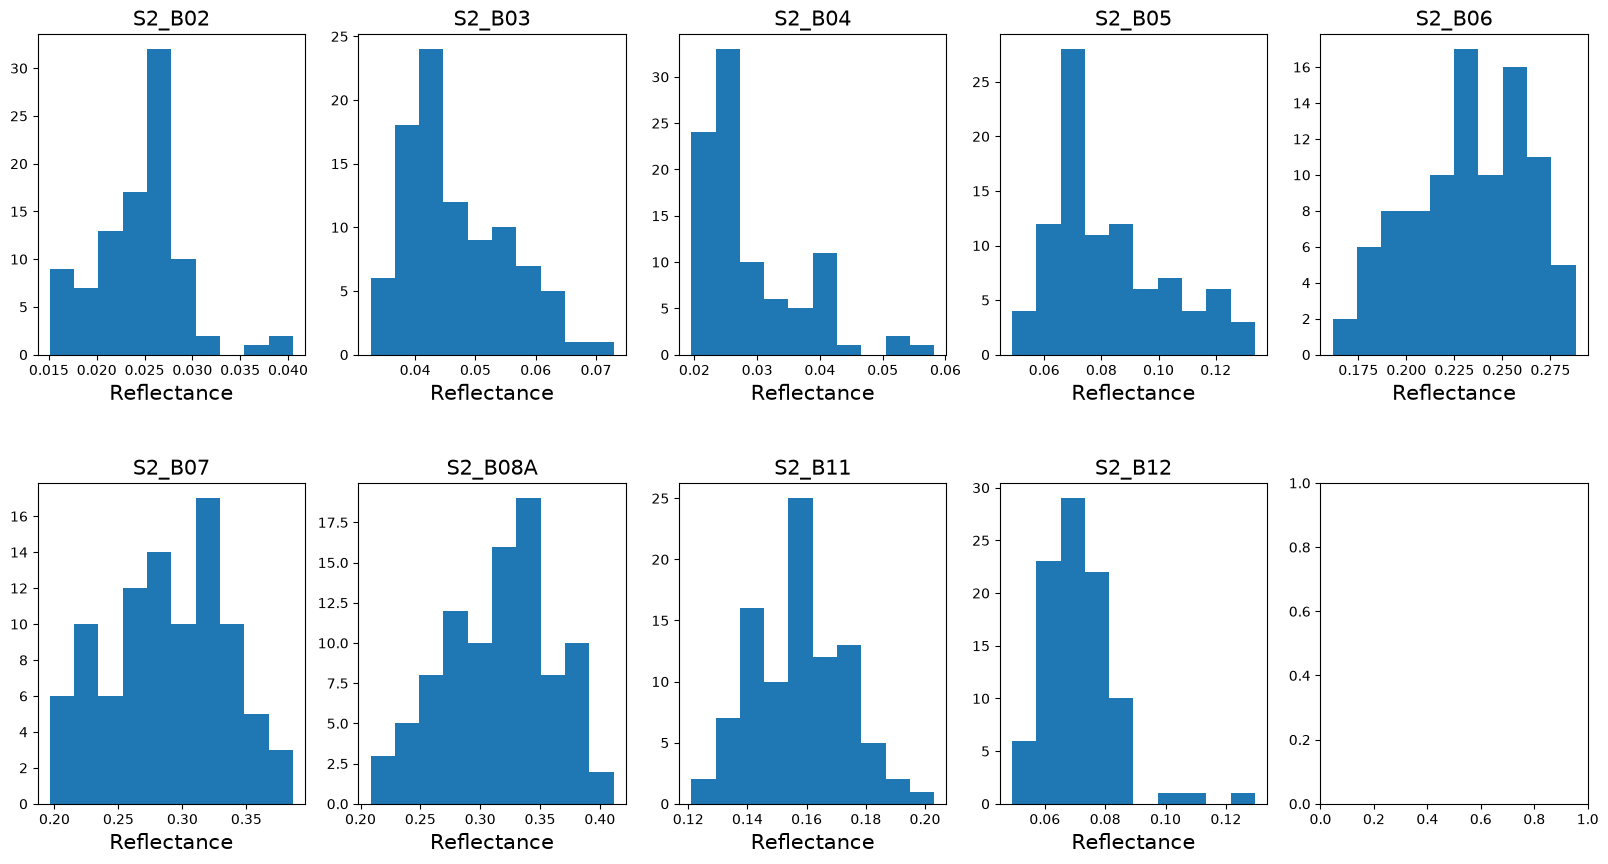

In [31]:
fig, axs = plt.subplots(2, 5, figsize=(20, 10))
fig.subplots_adjust(hspace=0.4)
# <CORRECTION>
for i, ax in enumerate(axs.flat):
    if i < s2_spectra.shape[1]:
        ax.hist(s2_spectra[:, i])
        ax.set_title(bands[i], fontsize=fontsize)
        ax.set_xlabel('Reflectance', fontsize=fontsize)
plt.show()
# </CORRECTION>

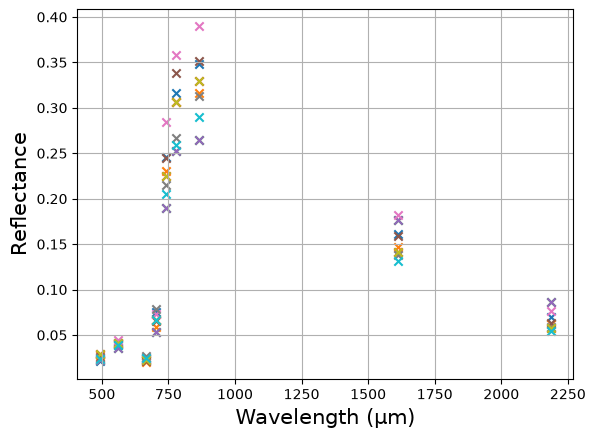

In [32]:
# <CORRECTION>
fig, ax = plt.subplots()
random_ids = np.random.randint(0, s2_spectra.shape[0], size=10)
for i in random_ids:
    plt.scatter(s2_central_wv, s2_spectra[i], marker='x')
ax.grid()
ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
ax.set_ylabel('Reflectance', fontsize=fontsize)
plt.show()
# </CORRECTION>

Update the LUT to match the data.

In [33]:
# <CORRECTION>
estimated_leaf_traits, closest_spectra = lut_inversion(s2_spectra, s2_reflectance_table[:, subset_bands], traits_table, top_k=1)

Car = estimated_leaf_traits[:, 0, 2:3]
Cab = estimated_leaf_traits[:, 0, 1:2]
Cw = estimated_leaf_traits[:, 0, 4:5] * 1000

estimated_leaf_traits = np.concatenate((Car, Cab, Cw), axis=1)
abs_error, relative_error, r2_score = inversion_metrics(estimated_leaf_traits, true_leaf_traits)
# </CORRECTION>

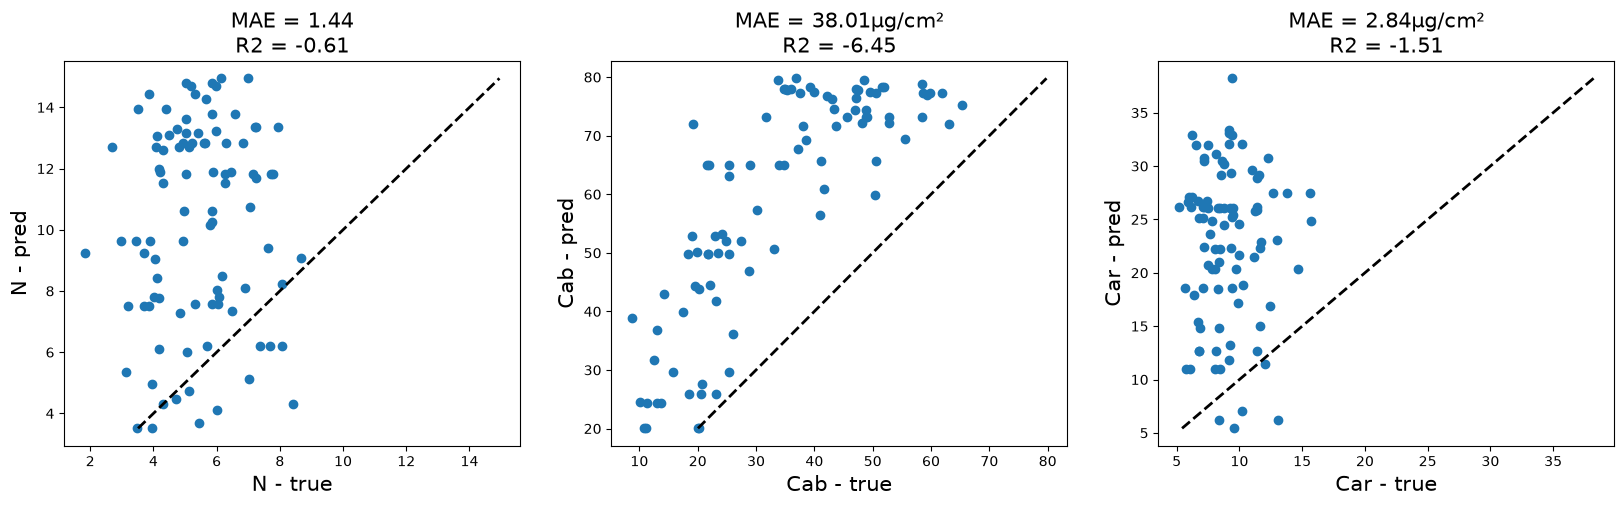

In [34]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
fig.subplots_adjust(hspace=0.4)

# <CORRECTION>
for i, ax in zip(range(len(leaf_traits)), axs.flat):
    x = np.linspace(estimated_leaf_traits[:, i].min(), estimated_leaf_traits[:, i].max(), 100)
    ax.plot(x, x, linestyle='--', lw=2, color='black')
    ax.scatter(true_leaf_traits[:, i], estimated_leaf_traits[:, i])
    ax.set_title(f'MAE = {abs_error[0, i]:.2f}' + units[i] + f'\nR2 = {r2_score[0,i]:.2f}', fontsize=fontsize)
    ax.set_ylabel(f'{trait_labels[i]} - pred', fontsize=fontsize)
    ax.set_xlabel(f'{trait_labels[i]} - true', fontsize=fontsize)
plt.show()
# </CORRECTION>

PROSPECT models the leaf optical properties, but one pixel of Sentinel-2 measures between 10m x 10m and 20m x 20m. What is modeled and what is observed are not on the same scales! 

Recent inversion methods use more complex models, such as DART, a 3D radiative transfer model: <br>
*Gastellu-Etchegorry, J.-P., N. Lauret, T. Yin, L. Landier, A. Kallel, Z. Malenovský, A. A. Bitar, et al. 2017. “DART: Recent Advances in Remote Sensing Data Modeling with Atmosphere, Polarization, and Chlorophyll Fluorescence.” IEEE Journal of Selected Topics in Applied Earth Observations & Remote Sensing 10 (6): 2640–2649. https://doi.org/10.1109/JSTARS.2017.2685528.*, used in this article: <br>
*Slanináková, T., Švik, M., Rebok, T., Hanousek, T., & Janoutová, R. (2025). Introducing a new adaptive look-up table subset selection method for leaf chlorophyll and carotenoids retrieval in broadleaved forests. Remote Sensing Letters, 16(6), 676–686. https://doi.org/10.1080/2150704X.2025.2495992*

In [37]:
### <CORRECTION> ###
import re
import nbformat

fname = "leaf_traits_inversion_correction.ipynb"  # ce fichier
fout  = fname.replace("_correction", "")

nb = nbformat.read(fname, as_version=4)

# 1. Remplacer les blocs <CORRECTION>...</CORRECTION> dans chaque cellule
pattern = re.compile(r"<CORRECTION>.*?</CORRECTION>", flags=re.DOTALL)
for cell in nb.cells:
    cell.source = pattern.sub(" TODO ", cell.source)

# 2. Supprimer la dernière cellule (celle-ci, qui génère la version étudiante)
nb.cells = nb.cells[:-1]

nbformat.write(nb, fout)
### </CORRECTION> ###